In [38]:
import geopandas as gpd
import pandas as pd
from matplotlib import pyplot as plt

In [39]:
locationcsv = pd.read_csv("/Users/patnaik/Documents/30DayMapChallenge/data/in-n-out.csv")
locationcsv

,store_name,city_name,state_id,lat,lng
0,Huntington Park,Huntington Park,CA,33.987,-118.225
1,Bell,Bell,CA,33.978,-118.187
2,Hollywood,Hollywood,CA,34.098,-118.342
3,Glendale (Brand & Broadway),Glendale,CA,34.146,-118.255
4,Glendale (Harvey & Holly),Glendale,CA,34.149,-118.227
...,...,...,...,...,...
438,Franklin,Franklin,TN,35.859,-86.842
439,Madison,Madison,TN,36.301,-86.696
440,Antioch,Antioch,TN,36.037,-86.653
441,Murfreesboro,Murfreesboro,TN,35.860,-86.441


In [51]:
stores = gpd.GeoDataFrame(
    locationcsv,
    geometry=gpd.points_from_xy(locations["lng"],locations["lat"]),
    crs='EPSG:4326'
)
stores.head()

,store_name,city_name,state_id,lat,lng,geometry
0,Huntington Park,Huntington Park,CA,33.987,-118.225,POINT (-118.225 33.987)
1,Bell,Bell,CA,33.978,-118.187,POINT (-118.187 33.978)
2,Hollywood,Hollywood,CA,34.098,-118.342,POINT (-118.342 34.098)
3,Glendale (Brand & Broadway),Glendale,CA,34.146,-118.255,POINT (-118.255 34.146)
4,Glendale (Harvey & Holly),Glendale,CA,34.149,-118.227,POINT (-118.227 34.149)


In [52]:
usa = gpd.read_file("/Users/patnaik/Documents/30DayMapChallenge/data/cb_2025_us_all_20m/cb_2025_us_state_20m/cb_2025_us_state_20m.shp")

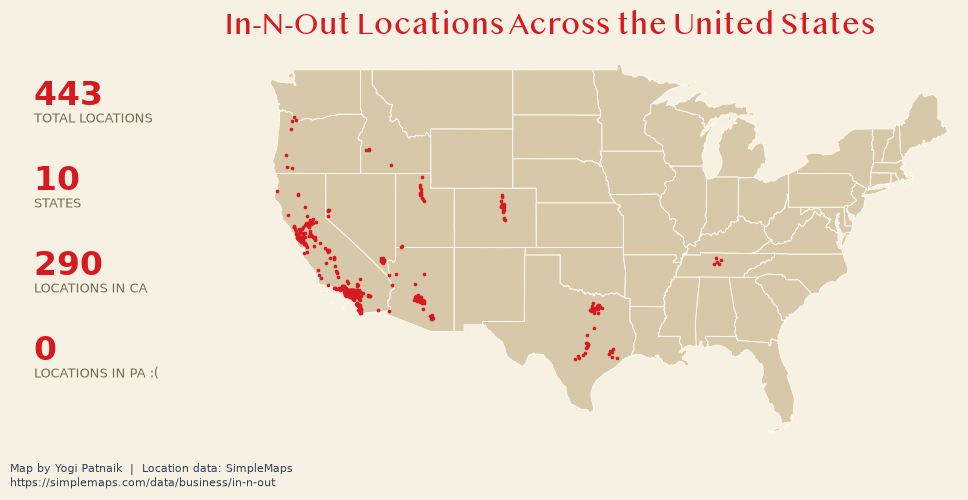

In [107]:
# Map
fig, ax = plt.subplots(figsize=(12,5))
fig.patch.set_facecolor("#F7F1E4")
ax.set_facecolor("#F7F1E4")
usa.plot(ax=ax, color="#D7C8AA", edgecolor="#FFF9ED", linewidth=0.7)
stores.plot(ax=ax, color="#D71920", markersize=7, linewidth=0)
fig.suptitle(
    "In-N-Out Locations Across the United States",
    fontsize=22,
    fontname="Sinhala MN",
    color="#D71920",
    x=0.46,
    y=0.97
)
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_axis_off()
ax.text(
    0.01, 0.01,
    "Map by Yogi Patnaik  |  Location data: SimpleMaps\n"
    "https://simplemaps.com/data/business/in-n-out",
    transform=fig.transFigure,
    fontsize=8,
    color="#334155",
    ha="left",
    va="bottom"
)
# Statistics
stats = [
    (f"{total_stores:,}", "TOTAL LOCATIONS"),
    (f"{total_states}", "STATES"),
    (f"{top_count:,}", f"LOCATIONS IN {top_state}"),
    ("0", "LOCATIONS IN PA :(")
]
for y, (value, label) in zip([0.78, 0.61, 0.44, 0.27], stats):
    fig.text(
        0.03, y, value,
        ha="left",
        fontsize=24,
        fontweight="bold",
        color="#D71920"
    )

    fig.text(
        0.03, y - 0.035, label,
        ha="left",
        fontsize=9,
        color="#776B59"
    )
plt.show()